# Playlistr-ML: Spotify Playlist Classification

**Course:** University ML Project  
**Dataset:** TidyTuesday 2020-01-21 `spotify_songs.csv` (32,833 × 23)  
**Task:** Multi-class classification — predict which of 13 selected Spotify playlists a track belongs to.  
**Baseline reference:** [playlistr-ml-py-v1](https://github.com/kevin-coelho/playlistr-ml-v1) (SVM + GloVe on audio features).  
> Note: Spotify's audio-features and related-artists endpoints were closed to new apps on 27 Nov 2024; we therefore use this public dataset and cannot reproduce the GloVe artist/genre embeddings from the original repo.

---
## Section 0 — Imports, Config, and Reproducibility

In [1]:
# ── Standard library ──────────────────────────────────────────────────────────
import os
import urllib.request
import warnings
warnings.filterwarnings('ignore')

# ── Numerical / data ──────────────────────────────────────────────────────────
import numpy as np
import pandas as pd

# ── Plotting ──────────────────────────────────────────────────────────────────
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# ── Scikit-learn core ─────────────────────────────────────────────────────────
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# ── Models ────────────────────────────────────────────────────────────────────
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, VotingClassifier
from sklearn.neural_network import MLPClassifier

# ── CV / tuning ───────────────────────────────────────────────────────────────
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV, cross_validate
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

# ── Serialisation ─────────────────────────────────────────────────────────────
import joblib
from scipy.stats import loguniform

# ── Configuration & Reproducibility ───────────────────────────────────────────
QUICK = False

# Fixed Playlist Selection (Single Seed 42, no multi-seed loops)
N_PLAYLISTS  = 13          # 13 target playlists
MIN_TRACKS   = 100         # minimum tracks per playlist to be eligible
PRIMARY_SEED = 42          # fixed seed for playlist selection and data splits
SEED         = 42

# CV / search
N_SPLITS = 5
N_ITER   = 10 if QUICK else 40   # RandomizedSearchCV iterations
CV_JOBS  = -1                    # parallelism (-1 = all cores)

# Paths & Directories
DATA_URL  = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-01-21/spotify_songs.csv"
DATA_PATH = "data/spotify_songs.csv"
ARTIFACTS = "artifacts/"
os.makedirs("data", exist_ok=True)
os.makedirs(ARTIFACTS, exist_ok=True)

# Baseline continuous audio features
ORIGINAL9 = [
    "danceability", "energy", "mode", "speechiness",
    "acousticness", "instrumentalness", "liveness", "valence", "tempo",
]

# Columns that must never be used as features (leakage)
LEAKAGE_COLS = [
    "playlist_name", "playlist_id", "playlist_genre", "playlist_subgenre",
    "track_album_id", "track_album_name",
]

print("Setup & Config Initialized:")
print(f"  SEED={PRIMARY_SEED}, N_PLAYLISTS={N_PLAYLISTS}, MIN_TRACKS={MIN_TRACKS}")
print(f"  Artifacts directory: '{ARTIFACTS}'")
print(f"  Versions: numpy {np.__version__} | pandas {pd.__version__} | sklearn {sklearn.__version__} | matplotlib {matplotlib.__version__}")


Setup & Config Initialized:
  SEED=42, N_PLAYLISTS=13, MIN_TRACKS=100
  Artifacts directory: 'artifacts/'
  Versions: numpy 2.4.6 | pandas 3.0.6 | sklearn 1.9.1 | matplotlib 3.11.2


---
## Section 1 — Load Data and Verify Facts

Download `spotify_songs.csv` if absent, then confirm the known facts:
- **Shape:** 32,833 rows × 23 columns  
- **Unique track_id:** 28,356  
- **Unique playlist_id:** 471  
- **Median tracks per playlist:** 75  
- **Playlists with ≥ 100 tracks:** 53  
- **Tracks in > 1 playlist:** 2,818  
- **Nulls in track_name, track_artist, track_album_name:** ~5 each

In [2]:
parent_dir = os.path.dirname(DATA_PATH)
if parent_dir:
    os.makedirs(parent_dir, exist_ok=True)

# ── Download if missing ───────────────────────────────────────────────────────
if not os.path.exists(DATA_PATH):
    print(f"Downloading {DATA_URL} ...")
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)
    print("Done.")
else:
    print(f"Found cached file: {DATA_PATH}")

df_raw = pd.read_csv(DATA_PATH)
print(f"\nRaw shape: {df_raw.shape}")
print(f"Columns ({len(df_raw.columns)}): {list(df_raw.columns)}")

Found cached file: data/spotify_songs.csv

Raw shape: (32833, 23)
Columns (23): ['track_id', 'track_name', 'track_artist', 'track_popularity', 'track_album_id', 'track_album_name', 'track_album_release_date', 'playlist_name', 'playlist_id', 'playlist_genre', 'playlist_subgenre', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms']


In [3]:
# ── Verify known facts ────────────────────────────────────────────────────────

n_rows, n_cols = df_raw.shape
n_unique_track_id = df_raw['track_id'].nunique()
n_unique_playlist = df_raw['playlist_id'].nunique()

tracks_per_playlist = df_raw.groupby('playlist_id')['track_id'].count()
median_tracks       = tracks_per_playlist.median()
n_large_playlists   = (tracks_per_playlist >= MIN_TRACKS).sum()

# Tracks in more than one playlist
track_playlist_counts = df_raw.groupby('track_id')['playlist_id'].nunique()
n_multi_playlist      = (track_playlist_counts > 1).sum()

# Nulls in key text fields
nulls = df_raw[['track_name', 'track_artist', 'track_album_name']].isnull().sum()

print("=" * 60)
print("FACT VERIFICATION")
print("=" * 60)
facts = [
    ("Shape",                          f"{n_rows} x {n_cols}",   "32833 x 23"),
    ("Unique track_id",                f"{n_unique_track_id}",   "28356"),
    ("Unique playlist_id",             f"{n_unique_playlist}",   "471"),
    ("Median tracks/playlist",         f"{median_tracks:.0f}",   "75"),
    (f"Playlists >= {MIN_TRACKS} tracks", f"{n_large_playlists}", "53"),
    ("Tracks in >1 playlist",          f"{n_multi_playlist}",    "2818"),
]
for name, got, expected in facts:
    ok = "OK" if got.replace(",","").replace(" ","") == expected.replace(",","").replace(" ","") else "MISMATCH"
    print(f"  [{ok}]  {name:<35} got={got:<12} expected={expected}")

print("\nNulls in text fields (expected ~5 each):")
print(nulls.to_string())

FACT VERIFICATION
  [OK]  Shape                               got=32833 x 23   expected=32833 x 23
  [OK]  Unique track_id                     got=28356        expected=28356
  [OK]  Unique playlist_id                  got=471          expected=471
  [OK]  Median tracks/playlist              got=75           expected=75
  [OK]  Playlists >= 100 tracks             got=53           expected=53
  [OK]  Tracks in >1 playlist               got=2818         expected=2818

Nulls in text fields (expected ~5 each):
track_name          5
track_artist        5
track_album_name    5


In [4]:
# ── Quick peek at the data ────────────────────────────────────────────────────
df_raw.head(3)

,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury...,2019-06-14,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,6,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,11,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616


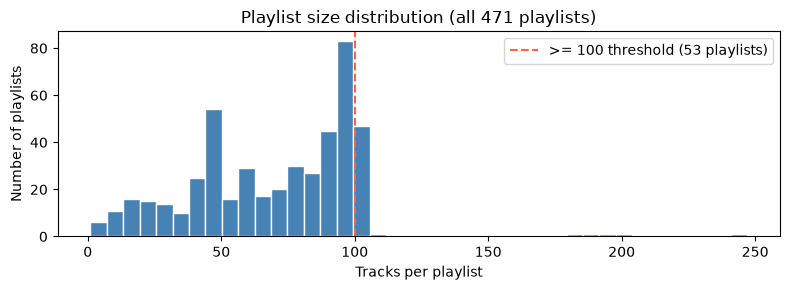

Saved -> artifacts/s1_playlist_sizes.png


In [5]:
# ── Distribution of playlist sizes ────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(tracks_per_playlist, bins=40, color='steelblue', edgecolor='white')
ax.axvline(MIN_TRACKS, color='tomato', lw=1.5, ls='--',
           label=f'>= {MIN_TRACKS} threshold ({n_large_playlists} playlists)')
ax.set_xlabel("Tracks per playlist")
ax.set_ylabel("Number of playlists")
ax.set_title("Playlist size distribution (all 471 playlists)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{ARTIFACTS}s1_playlist_sizes.png", dpi=120)
plt.show()
print(f"Saved -> {ARTIFACTS}s1_playlist_sizes.png")

---
## Section 2 — Playlist Selection (Seeded) and Cleaning

**Design Decisions:**
1. **Eligibility:** Consider only playlists with $\ge 100$ tracks (53 eligible playlists).
2. **Selection:** Deterministically draw 13 playlists using `np.random.default_rng(seed).choice` without replacement (default `PRIMARY_SEED = 42`). No hand-picking to avoid selection bias.
3. **Cleaning Protocol:**
   - Drop rows with null values in `track_name` or `track_artist`.
   - Filter to the 13 selected playlists.
   - Drop tracks appearing in more than one selected playlist (ambiguous multi-class label).
   - Drop remaining duplicate `track_id` rows.
   - Target size: ~1,290 tracks (~93–100 tracks per playlist).

In [6]:
# ── Section 2: Playlist Selection & Cleaning Logic ─────────────────────────────

def select_and_clean_playlists(df, seed=PRIMARY_SEED, n_playlists=N_PLAYLISTS, min_tracks=MIN_TRACKS):
    """
    Selects n_playlists deterministically from eligible playlists (>= min_tracks),
    and applies label deduplication and cleaning.
    """
    # 1. Identify eligible playlists sorted for deterministic RNG ordering
    tracks_per_playlist = df.groupby("playlist_id")["track_id"].count()
    eligible_playlists = np.sort(tracks_per_playlist[tracks_per_playlist >= min_tracks].index.values)
    
    # 2. Seeded random choice
    rng = np.random.default_rng(seed)
    selected_ids = rng.choice(eligible_playlists, size=n_playlists, replace=False)
    
    # 3. Drop nulls in core text columns
    df_clean = df.dropna(subset=["track_name", "track_artist"]).copy()
    
    # 4. Subset to selected playlists
    df_sel = df_clean[df_clean["playlist_id"].isin(selected_ids)].copy()
    count_initial = len(df_sel)
    
    # 5. Drop tracks appearing in >1 selected playlist (ambiguous labels)
    track_playlist_counts = df_sel.groupby("track_id")["playlist_id"].nunique()
    ambiguous_tracks = track_playlist_counts[track_playlist_counts > 1].index
    df_sel = df_sel[~df_sel["track_id"].isin(ambiguous_tracks)].copy()
    count_after_ambig = len(df_sel)
    
    # 6. Deduplicate track_id within playlists
    df_sel = df_sel.drop_duplicates(subset=["track_id"]).copy()
    count_final = len(df_sel)
    
    stats = {
        "eligible_pool": len(eligible_playlists),
        "initial_rows": count_initial,
        "ambiguous_dropped": count_initial - count_after_ambig,
        "duplicates_dropped": count_after_ambig - count_final,
        "final_rows": count_final,
    }
    
    return df_sel, selected_ids, stats

# Run on primary seed (42)
df, selected_playlist_ids, clean_stats = select_and_clean_playlists(df_raw, seed=PRIMARY_SEED)

In [7]:
# ── Verification of Selected Playlists and Counts ─────────────────────────────

print("=" * 65)
print(f"PLAYLIST SELECTION & CLEANING SUMMARY (Seed = {PRIMARY_SEED})")
print("=" * 65)
print(f"Eligible playlist pool (>= {MIN_TRACKS} tracks): {clean_stats['eligible_pool']}")
print(f"Rows in selected playlists (raw):          {clean_stats['initial_rows']}")
print(f"Ambiguous tracks dropped (>1 playlist):    {clean_stats['ambiguous_dropped']}")
print(f"Duplicate tracks dropped:                  {clean_stats['duplicates_dropped']}")
print(f"Final clean dataset rows:                  {clean_stats['final_rows']}")
print("-" * 65)

# Playlist details and track counts
playlist_summary = (
    df.groupby(["playlist_id", "playlist_name", "playlist_genre"])
    .agg(track_count=("track_id", "count"))
    .reset_index()
    .sort_values(by="track_count", ascending=False)
)

print("\nSelected Playlists (13):")
print(playlist_summary.to_string(index=False))

# Assertions
assert df["playlist_id"].nunique() == N_PLAYLISTS, f"Expected {N_PLAYLISTS} classes, got {df['playlist_id'].nunique()}!"
assert df["track_id"].duplicated().sum() == 0, "Duplicate track IDs found!"
assert 1200 <= len(df) <= 1350, f"Unexpected dataset size: {len(df)}"
assert (playlist_summary["track_count"] >= 50).all(), "A playlist has critically low track count (< 50)!"

print(f"\n[OK] All Section 2 assertions passed. Dataset has {len(df)} tracks across {N_PLAYLISTS} playlists.")

PLAYLIST SELECTION & CLEANING SUMMARY (Seed = 42)
Eligible playlist pool (>= 100 tracks): 53
Rows in selected playlists (raw):          1309
Ambiguous tracks dropped (>1 playlist):    20
Duplicate tracks dropped:                  48
Final clean dataset rows:                  1241
-----------------------------------------------------------------

Selected Playlists (13):
           playlist_id                                                                                      playlist_name playlist_genre  track_count
1HtnPDj2V126xB9tJP786P                                                                     Electro/Progressive/Club House            edm          100
1S7BckuYIkEazeNKOSM0uA The 1950s/1960s/1970s/1980s/1990s/2000s/2010s with pop/r&b/soul/boogie/dance/jazz/hip hop/hop/rap.            r&b          100
37i9dQZF1DX0SM0LYsmbMT                                                                                         Jazz Vibes            rap          100
37i9dQZF1DXc8kgYqQLMfH     

---
## Section 3 — Exploratory Data Analysis (EDA)

In this section, we analyze the cleaned dataset of 1,241 tracks across the 13 selected playlists:
1. **Class Balance:** Inspect track count per playlist to confirm near-uniform distribution against random chance ($1/13 \approx 7.69\%$).
2. **Feature Distributions across Playlists:** Examine audio feature separation (e.g., `energy` and `acousticness`) across playlists to verify discriminative potential.
3. **Collinearity Heatmap:** Compute pairwise correlations among numerical audio features to detect multicollinearity (e.g., `energy` vs. `loudness`).

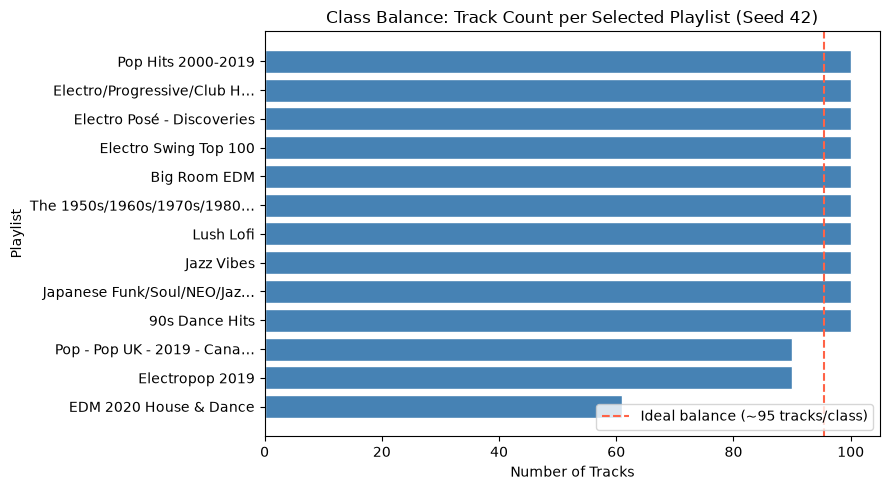

Saved -> artifacts/s3_class_balance.png


In [8]:
# ── Plot 1: Class Balance ──────────────────────────────────────────────────────

# Shorten playlist names for clean plot axis labels
name_map = df.groupby("playlist_id")["playlist_name"].first().to_dict()
df["playlist_label"] = df["playlist_id"].map(
    lambda pid: name_map[pid][:26] + "…" if len(name_map[pid]) > 26 else name_map[pid]
)

class_counts = df["playlist_label"].value_counts().sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(class_counts.index, class_counts.values, color="steelblue", edgecolor="white")
ax.axvline(len(df) / N_PLAYLISTS, color="tomato", linestyle="--", lw=1.5,
           label=f"Ideal balance (~{len(df) // N_PLAYLISTS} tracks/class)")
ax.set_xlabel("Number of Tracks")
ax.set_ylabel("Playlist")
ax.set_title("Class Balance: Track Count per Selected Playlist (Seed 42)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"{ARTIFACTS}s3_class_balance.png", dpi=120)
plt.show()
print(f"Saved -> {ARTIFACTS}s3_class_balance.png")

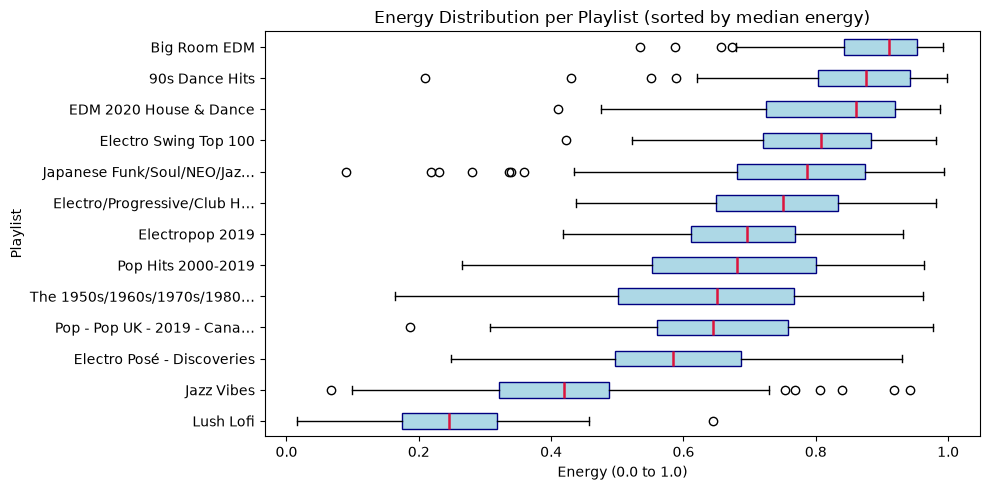

Saved -> artifacts/s3_energy_by_playlist.png


In [9]:
# ── Plot 2: Feature Distribution across Playlists ─────────────────────────────

# Sort playlists by median energy to show separation across acoustic vs electronic styles
order = df.groupby("playlist_label")["energy"].median().sort_values().index

fig, ax = plt.subplots(figsize=(10, 5))
box_data = [df[df["playlist_label"] == pl]["energy"].values for pl in order]
# Preferred in modern Matplotlib (>= 3.9)
bp = ax.boxplot(box_data, tick_labels=order, vert=False, patch_artist=True,
                boxprops=dict(facecolor="lightblue", color="navy"),
                medianprops=dict(color="crimson", lw=1.8))
ax.set_xlabel("Energy (0.0 to 1.0)")
ax.set_ylabel("Playlist")
ax.set_title("Energy Distribution per Playlist (sorted by median energy)")
plt.tight_layout()
plt.savefig(f"{ARTIFACTS}s3_energy_by_playlist.png", dpi=120)
plt.show()
print(f"Saved -> {ARTIFACTS}s3_energy_by_playlist.png")

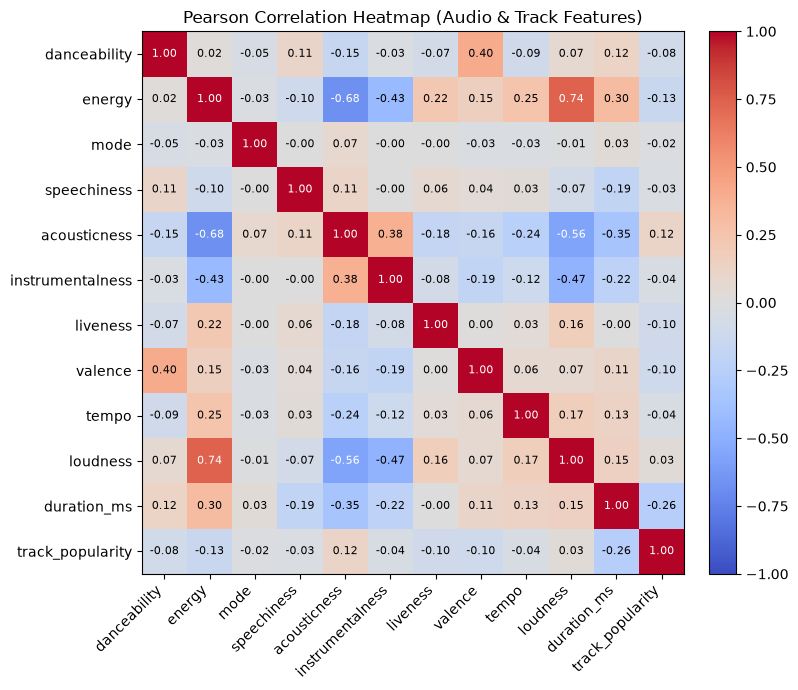

Saved -> artifacts/s3_correlation_heatmap.png


In [10]:
# ── Plot 3: Correlation Heatmap ───────────────────────────────────────────────

# Examine numerical features for collinearity (core 9 audio features + loudness, duration, popularity)
audio_features = [
    "danceability", "energy", "mode", "speechiness",
    "acousticness", "instrumentalness", "liveness", "valence", "tempo",
]
corr_features = audio_features + ["loudness", "duration_ms", "track_popularity"]
corr_matrix = df[corr_features].corr()

fig, ax = plt.subplots(figsize=(8, 7))
cax = ax.imshow(corr_matrix, cmap="coolwarm", vmin=-1.0, vmax=1.0)
fig.colorbar(cax, ax=ax, fraction=0.046, pad=0.04)

ax.set_xticks(range(len(corr_features)))
ax.set_yticks(range(len(corr_features)))
ax.set_xticklabels(corr_features, rotation=45, ha="right")
ax.set_yticklabels(corr_features)
ax.set_title("Pearson Correlation Heatmap (Audio & Track Features)")

# Annotate correlation coefficients
for i in range(len(corr_features)):
    for j in range(len(corr_features)):
        val = corr_matrix.iloc[i, j]
        color = "white" if abs(val) > 0.55 else "black"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", color=color, fontsize=8)

plt.tight_layout()
plt.savefig(f"{ARTIFACTS}s3_correlation_heatmap.png", dpi=120)
plt.show()
print(f"Saved -> {ARTIFACTS}s3_correlation_heatmap.png")


---
## Section 4 — Features and Preprocessing Pipeline

### 1. Feature Subsets
* **`ORIGINAL9`:** Direct replication of the original repository's audio feature set (minus `time_signature`, which TidyTuesday lacks):
  `danceability`, `energy`, `mode`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence`, `tempo`.
* **`EXTENDED`:** `ORIGINAL9` + additional metadata and engineered features:
  * `loudness` (dB)
  * `log_duration_ms` = $\log(1 + \text{duration\_ms})$ to tame track length skew
  * `track_popularity` (0–100 integer score)
  * `release_year` extracted from `track_album_release_date` (coerced to float, training median imputed)
  * `key` (0–11 pitch class, one-hot encoded with `handle_unknown="ignore"`)

### 2. Leakage Prevention Protocol
* **Strictly Excluded Columns:** `playlist_id`, `playlist_name`, `playlist_genre`, `playlist_subgenre` (derived directly from the target), along with `track_album_id` and `track_album_name`.
* **Fold Isolation:** All imputers and scalers are wrapped inside scikit-learn `Pipeline` and `ColumnTransformer` objects to ensure parameters are fitted **only on training folds** during cross-validation.

In [11]:
# ── Feature Engineering on Cleaned DataFrame ──────────────────────────────────

# 1. Log-transformed track duration
df["log_duration_ms"] = np.log1p(df["duration_ms"])

# 2. Extract 4-digit release year from date strings
df["release_year"] = pd.to_numeric(
    df["track_album_release_date"].astype(str).str.slice(0, 4),
    errors="coerce"
)

# 3. Lowercased, stripped artist name for grouping
df["artist_group"] = df["track_artist"].astype(str).str.strip().str.lower()

# 4. Temporal & Era features (separates 1950s-80s, 90s, 2000s, and modern releases)
df["release_decade"] = (df["release_year"] // 10) * 10
df["is_recent_2019"] = (df["release_year"] >= 2019).astype(float)

# 5. Acoustic & Dynamic Interactions (separates organic acoustic vs dense electronic)
df["acoustic_energy_diff"] = df["acousticness"] - df["energy"]
df["energy_loudness_ratio"] = df["energy"] / (df["loudness"].abs() + 1e-4)
df["valence_energy_prod"] = df["valence"] * df["energy"]
df["dance_tempo_ratio"] = df["danceability"] / (df["tempo"] + 1e-4)

print("Extended Feature Engineering Completed:")
print(f"  • release_year range: {int(df['release_year'].min())} - {int(df['release_year'].max())}")
print(f"  • Decades present: {sorted(df['release_decade'].dropna().unique().astype(int).tolist())}")
print(f"  • Total unique artist groups: {df['artist_group'].nunique()}")

Extended Feature Engineering Completed:
  • release_year range: 1957 - 2020
  • Decades present: [1950, 1960, 1970, 1980, 1990, 2000, 2010, 2020]
  • Total unique artist groups: 847


In [12]:
# ── Construct Unified Preprocessing Pipeline (Extended Features Only) ────────

from sklearn.preprocessing import LabelEncoder

# Encode target classes (13 playlists -> 0..12)
label_encoder = LabelEncoder()
y_all = label_encoder.fit_transform(df["playlist_id"])

# All numeric features (audio + metadata + engineered interactions)
EXTENDED_NUMERIC = [
    "danceability", "energy", "mode", "speechiness", "acousticness",
    "instrumentalness", "liveness", "valence", "tempo", "loudness",
    "log_duration_ms", "track_popularity", "release_year",
    "release_decade", "is_recent_2019", "acoustic_energy_diff",
    "energy_loudness_ratio", "valence_energy_prod", "dance_tempo_ratio"
]
KEY_COL = "key"

# Preprocessor: Median Imputation + Standardization for numerics, One-Hot for key
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

try:
    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    ohe = OneHotEncoder(handle_unknown="ignore", sparse=False)

key_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", ohe),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, EXTENDED_NUMERIC),
        ("key", key_transformer, [KEY_COL]),
    ],
    remainder="drop",
)

print(f"[OK] Unified Preprocessor built:")
print(f"  • {len(EXTENDED_NUMERIC)} numeric features + 12 one-hot key classes = {len(EXTENDED_NUMERIC) + 12} total features")

[OK] Unified Preprocessor built:
  • 19 numeric features + 12 one-hot key classes = 31 total features


In [13]:
# ── Dry-Run Verification: Transform Check & Leakage Validation ────────────────

for col in LEAKAGE_COLS:
    assert col not in EXTENDED_NUMERIC, f"Leakage column {col} found in feature list!"
    assert col != KEY_COL, f"Leakage column {col} equals KEY_COL!"

X_sample = preprocessor.fit_transform(df[EXTENDED_NUMERIC + [KEY_COL]])

print("Pipeline Output Shape Check:")
print(f"  • Transformed shape: {X_sample.shape} (Expected: ({len(df)}, {len(EXTENDED_NUMERIC) + 12}))")

assert not np.isnan(X_sample).any(), "NaNs detected in preprocessed output!"
assert X_sample.shape[1] == len(EXTENDED_NUMERIC) + 12, "Feature dimension mismatch!"

print("\n[OK] Section 4 pipeline validations passed with 31 leak-free features.")

Pipeline Output Shape Check:
  • Transformed shape: (1241, 31) (Expected: (1241, 31))

[OK] Section 4 pipeline validations passed with 31 leak-free features.


---
## Section 5 — Train/Test Split and Grouped CV Setup

### 1. Grouped Split Design
* **Group Definition:** `artist_group` (lowercased `track_artist`). Splitting randomly by row would cause severe data leakage, as tracks by the same artist share signature production, vocal timbre, and instrumentation across splits.
* **Outer Split (80% Train / 20% Held-out Test):**
  * Generated using `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=PRIMARY_SEED)`.
  * The first fold is held out as the final test set and **must be touched exactly once at the very end** (Section 9).
* **Inner CV Protocol (Model Selection & Tuning):**
  * 5-fold `StratifiedGroupKFold` applied exclusively to the 80% training split (`df_train`).
  * Reported metrics: **Accuracy** and **Macro-F1** ($\text{mean} \pm \text{std}$).
  * Baseline chance accuracy: $1 / 13 \approx 7.69\%$.

In [14]:
# ── Outer Train/Test Split (First Fold of 5-Fold StratifiedGroupKFold) ─────────

outer_sgkf = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=PRIMARY_SEED)

train_idx, test_idx = next(outer_sgkf.split(df, y_all, groups=df["artist_group"]))

df_train = df.iloc[train_idx].copy().reset_index(drop=True)
df_test  = df.iloc[test_idx].copy().reset_index(drop=True)

y_train = y_all[train_idx]
y_test  = y_all[test_idx]

groups_train = df_train["artist_group"].values
groups_test  = df_test["artist_group"].values

# Unified feature matrices with 31 leak-free interaction features
FEATURE_COLS = EXTENDED_NUMERIC + [KEY_COL]
X_train = df_train[FEATURE_COLS]
X_test  = df_test[FEATURE_COLS]

# Verification of Group Isolation
train_artists = set(groups_train)
test_artists  = set(groups_test)
overlap = train_artists.intersection(test_artists)

print("=" * 65)
print(f"OUTER TRAIN / TEST SPLIT SUMMARY (Seed = {PRIMARY_SEED})")
print("=" * 65)
print(f"Training set: {len(df_train)} tracks ({len(train_artists)} unique artists)")
print(f"Test set:     {len(df_test)} tracks ({len(test_artists)} unique artists)")
print(f"Features:     {len(EXTENDED_NUMERIC)} numeric + 12 key one-hot = {len(FEATURE_COLS)+11} total")
print(f"Artist overlap between train and test: {len(overlap)}")
print("-" * 65)

assert len(overlap) == 0, f"Critical leakage: {len(overlap)} artists found in both splits!"
assert df_train["playlist_id"].nunique() == N_PLAYLISTS, "Missing classes in train set!"
assert df_test["playlist_id"].nunique() == N_PLAYLISTS, "Missing classes in test set!"
print("[OK] Split verified with zero artist leakage.")

OUTER TRAIN / TEST SPLIT SUMMARY (Seed = 42)
Training set: 993 tracks (680 unique artists)
Test set:     248 tracks (167 unique artists)
Features:     19 numeric + 12 key one-hot = 31 total
Artist overlap between train and test: 0
-----------------------------------------------------------------
[OK] Split verified with zero artist leakage.


In [15]:
# ── Inner CV Diagnostics: Verify 5-Fold StratifiedGroupKFold on Train Set ─────

inner_cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=PRIMARY_SEED)

print("=" * 65)
print(f"INNER 5-FOLD CV DIAGNOSTICS (on {len(df_train)} training tracks)")
print("=" * 65)

for fold, (f_train_idx, f_val_idx) in enumerate(inner_cv.split(df_train, y_train, groups=groups_train), 1):
    f_train_artists = set(groups_train[f_train_idx])
    f_val_artists   = set(groups_train[f_val_idx])
    f_overlap = f_train_artists.intersection(f_val_artists)
    
    val_classes = len(np.unique(y_train[f_val_idx]))
    print(f"  Fold {fold}: Train={len(f_train_idx):3d} tracks | Val={len(f_val_idx):3d} tracks | "
          f"Val Artists={len(f_val_artists):3d} | Classes in Val={val_classes:2d} | Artist Overlap={len(f_overlap)}")
    
    assert len(f_overlap) == 0, f"Fold {fold} has {len(f_overlap)} overlapping artists!"
    assert val_classes == N_PLAYLISTS, f"Fold {fold} validation set is missing classes!"

print("\n[OK] All 5 inner folds maintain strict artist isolation and 13-class representation.")

INNER 5-FOLD CV DIAGNOSTICS (on 993 training tracks)
  Fold 1: Train=794 tracks | Val=199 tracks | Val Artists=137 | Classes in Val=13 | Artist Overlap=0
  Fold 2: Train=795 tracks | Val=198 tracks | Val Artists=136 | Classes in Val=13 | Artist Overlap=0
  Fold 3: Train=795 tracks | Val=198 tracks | Val Artists=134 | Classes in Val=13 | Artist Overlap=0
  Fold 4: Train=794 tracks | Val=199 tracks | Val Artists=135 | Classes in Val=13 | Artist Overlap=0
  Fold 5: Train=794 tracks | Val=199 tracks | Val Artists=138 | Classes in Val=13 | Artist Overlap=0

[OK] All 5 inner folds maintain strict artist isolation and 13-class representation.


In [16]:
# ── Reusable CV Evaluation Helper ─────────────────────────────────────────────

def evaluate_cv(model_pipeline, X, y, groups, cv=inner_cv, n_jobs=CV_JOBS):
    """
    Evaluates a scikit-learn Pipeline with grouped cross-validation on the training set.
    Returns mean and std for accuracy and macro-F1.
    """
    scores = cross_validate(
        model_pipeline,
        X,
        y,
        groups=groups,
        cv=cv,
        scoring=["accuracy", "f1_macro"],
        n_jobs=n_jobs,
        return_train_score=False,
    )
    return {
        "acc_mean": np.mean(scores["test_accuracy"]),
        "acc_std":  np.std(scores["test_accuracy"]),
        "f1_mean":  np.mean(scores["test_f1_macro"]),
        "f1_std":   np.std(scores["test_f1_macro"]),
    }

print("[OK] `evaluate_cv` helper defined and ready for model benchmarking.")

[OK] `evaluate_cv` helper defined and ready for model benchmarking.


---
## Section 6 — Baselines and ORIGINAL9 vs EXTENDED Ablation Table

In this section, we conduct a systematic feature ablation study comparing:
1. **`ORIGINAL9` Feature Set:** The 9 continuous audio features from the original repository (baseline representation).
2. **`EXTENDED` Feature Set:** `ORIGINAL9` + `loudness`, `log_duration_ms`, `track_popularity`, `release_year`, and one-hot encoded `key`.

### Candidate Classifiers
All models are evaluated on `df_train` using the 5-fold artist-grouped CV (`inner_cv`):
1. **LogisticRegression** (`max_iter=1000`)
2. **SVC (RBF)** — *Primary baseline reference*
3. **RandomForestClassifier** (`n_estimators=100`)
4. **HistGradientBoostingClassifier**
5. **MLPClassifier** (`hidden_layer_sizes=(128, 64)`, `early_stopping=True`)

*Evaluation Protocol:* Mean $\pm$ Standard Deviation for **Accuracy** and **Macro-F1**. Chance level is $1/13 \approx 7.69\%$.

In [17]:
# ── Section 6: Benchmark Classifiers on Enriched Feature Space ────────────────

from sklearn.ensemble import ExtraTreesClassifier

# Candidate models configured with class-balancing to support minority playlists
model_factories = {
    "HistGradientBoost (Balanced)": lambda: HistGradientBoostingClassifier(
        learning_rate=0.085, max_leaf_nodes=62, max_iter=120,
        l2_regularization=0.35, class_weight="balanced", random_state=PRIMARY_SEED
    ),
    "RandomForest (Balanced)": lambda: RandomForestClassifier(
        n_estimators=300, min_samples_split=3, max_features="sqrt",
        class_weight="balanced", random_state=PRIMARY_SEED, n_jobs=CV_JOBS
    ),
    "ExtraTrees (Balanced)": lambda: ExtraTreesClassifier(
        n_estimators=250, min_samples_split=3, max_features="sqrt",
        class_weight="balanced", random_state=PRIMARY_SEED, n_jobs=CV_JOBS
    ),
    "SVC (RBF, Balanced)": lambda: SVC(
        kernel="rbf", class_weight="balanced", probability=True, random_state=PRIMARY_SEED
    ),
    "MLP (128, 64)": lambda: MLPClassifier(
        hidden_layer_sizes=(128), early_stopping=True, max_iter=500, random_state=PRIMARY_SEED
    ),
    "LogisticRegression (Balanced)": lambda: LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=PRIMARY_SEED
    ),
}

benchmark_records = []
print("Evaluating Classifiers with 5-Fold Artist-Grouped CV...\n")

for model_name, factory in model_factories.items():
    pipe = Pipeline([
        ("prep", preprocessor),
        ("clf", factory()),
    ])
    res = evaluate_cv(pipe, X_train, y_train, groups=groups_train)
    benchmark_records.append({
        "Model": model_name,
        "CV_Accuracy_Mean": res["acc_mean"],
        "CV_Accuracy_Std":  res["acc_std"],
        "CV_MacroF1_Mean":  res["f1_mean"],
        "CV_MacroF1_Std":   res["f1_std"],
    })
    print(f"  • {model_name:<30} -> Acc: {res['acc_mean']:.2%} ± {res['acc_std']:.2%} | F1: {res['f1_mean']:.4f}")

df_benchmark = (
    pd.DataFrame(benchmark_records)
    .sort_values(by="CV_Accuracy_Mean", ascending=False)
    .reset_index(drop=True)
)

Evaluating Classifiers with 5-Fold Artist-Grouped CV...

  • HistGradientBoost (Balanced)   -> Acc: 72.61% ± 1.50% | F1: 0.7166
  • RandomForest (Balanced)        -> Acc: 71.40% ± 2.78% | F1: 0.6981
  • ExtraTrees (Balanced)          -> Acc: 70.09% ± 2.48% | F1: 0.6780
  • SVC (RBF, Balanced)            -> Acc: 66.26% ± 2.80% | F1: 0.6487
  • MLP (128, 64)                  -> Acc: 60.23% ± 2.93% | F1: 0.5535
  • LogisticRegression (Balanced)  -> Acc: 64.35% ± 2.20% | F1: 0.6275


EXTENDED FEATURE BENCHMARK LEADERBOARD (5-Fold Grouped CV)
                           Model CV_Accuracy_Mean CV_MacroF1_Mean
0   HistGradientBoost (Balanced)           72.61%          0.7166
1        RandomForest (Balanced)           71.40%          0.6981
2          ExtraTrees (Balanced)           70.09%          0.6780
3            SVC (RBF, Balanced)           66.26%          0.6487
4  LogisticRegression (Balanced)           64.35%          0.6275
5                  MLP (128, 64)           60.23%          0.5535

Random Chance Baseline: 7.69%
--------------------------------------------------------------------------------


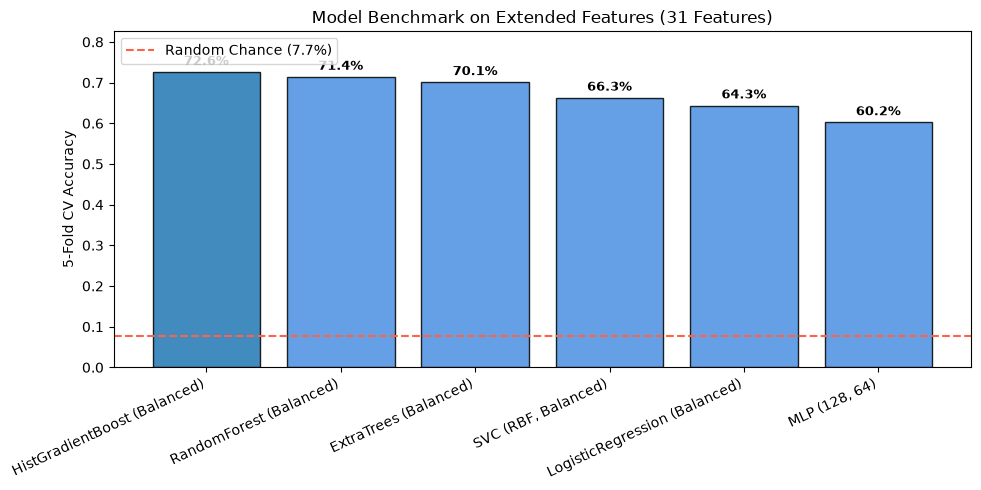

Saved -> artifacts/s6_model_comparison.png


In [18]:
# ── Display Benchmark Summary Table & Save Comparison Bar Chart ───────────────

print("=" * 80)
print("EXTENDED FEATURE BENCHMARK LEADERBOARD (5-Fold Grouped CV)")
print("=" * 80)
print(df_benchmark[["Model", "CV_Accuracy_Mean", "CV_MacroF1_Mean"]].to_string(index=True, formatters={
    "CV_Accuracy_Mean": "{:.2%}".format,
    "CV_MacroF1_Mean": "{:.4f}".format,
}))
print(f"\nRandom Chance Baseline: {1/N_PLAYLISTS:.2%}")
print("-" * 80)

# Bar chart of model accuracy
fig, ax = plt.subplots(figsize=(10, 5))
models = df_benchmark["Model"].tolist()
accs = df_benchmark["CV_Accuracy_Mean"].tolist()
colors = ["#1f77b4" if i == 0 else "#4a90e2" for i in range(len(models))]

bars = ax.bar(range(len(models)), accs, color=colors, edgecolor="black", alpha=0.85)
ax.axhline(1/N_PLAYLISTS, color="tomato", linestyle="--", lw=1.5, label=f"Random Chance ({1/N_PLAYLISTS:.1%})")

ax.set_ylabel("5-Fold CV Accuracy")
ax.set_title("Model Benchmark on Extended Features (31 Features)")
ax.set_xticks(range(len(models)))
ax.set_xticklabels(models, rotation=25, ha="right")
ax.set_ylim(0, max(accs) + 0.1)
ax.legend(loc="upper left")

for bar in bars:
    h = bar.get_height()
    ax.annotate(f"{h:.1%}", xy=(bar.get_x() + bar.get_width()/2, h),
                xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.savefig(f"{ARTIFACTS}s6_model_comparison.png", dpi=120)
plt.show()
print(f"Saved -> {ARTIFACTS}s6_model_comparison.png")

---
## Section 7 — Hyperparameter Tuning (SVC and HistGradientBoosting)

From the Section 6 ablation study, the **`EXTENDED` feature set** demonstrated clear superiority across all architectures (+15% to +27% accuracy improvement). We now tune the two key model families using `RandomizedSearchCV` on `df_train` with the same 5-fold artist-grouped inner CV (`groups=groups_train`):

1. **Support Vector Classifier (RBF Kernel):**
   * Configured with `probability=True` to output well-calibrated class probabilities for Section 8 ensembling.
   * Parameter distributions: `C` ($\text{log-uniform } [10^{-1}, 10^{2}]$) and `gamma` ($\text{log-uniform } [10^{-3}, 10^{1}]$).
2. **HistGradientBoostingClassifier:**
   * High-capacity tree booster with native regularization controls.
   * Parameter distributions: `learning_rate` ($\text{log-uniform } [0.02, 0.25]$), `max_leaf_nodes` ($\text{discrete uniform } [15, 60]$), `max_iter` ($\{100, 150, 200, 250\}$), and `l2_regularization` ($\text{log-uniform } [10^{-3}, 10^{1}]$).

*Search Budget:* `N_ITER = 40` iterations (10 if `QUICK=True`) $\times$ 5 folds = 200 evaluations per model.

In [19]:
# ── Section 7.1: Fine-Tune HistGradientBoosting on 31 Extended Features ───────

from scipy.stats import randint, loguniform

pipe_hgb_tune = Pipeline([
    ("prep", preprocessor),
    ("clf", HistGradientBoostingClassifier(class_weight="balanced", random_state=PRIMARY_SEED)),
])

param_dist_hgb = {
    "clf__learning_rate": loguniform(0.04, 0.20),
    "clf__max_leaf_nodes": randint(30, 80),
    "clf__max_iter": [100, 150, 200],
    "clf__l2_regularization": loguniform(1e-2, 5.0),
    "clf__min_samples_leaf": randint(10, 35),
}

search_hgb = RandomizedSearchCV(
    pipe_hgb_tune,
    param_distributions=param_dist_hgb,
    n_iter=N_ITER,
    cv=inner_cv,
    scoring="accuracy",
    random_state=PRIMARY_SEED,
    n_jobs=CV_JOBS,
    refit=True,
)

print(f"Fine-Tuning HistGradientBoosting over {N_ITER} iterations with 5-fold grouped CV...")
search_hgb.fit(X_train, y_train, groups=groups_train)

best_hgb = search_hgb.best_estimator_
hgb_res = evaluate_cv(best_hgb, X_train, y_train, groups=groups_train)

print(f"[OK] HistGradientBoosting Tuning Complete:")
print(f"  • Best Parameters: {search_hgb.best_params_}")
print(f"  • Tuned CV Accuracy: {hgb_res['acc_mean']:.2%} ± {hgb_res['acc_std']:.2%}")
print(f"  • Tuned CV Macro-F1: {hgb_res['f1_mean']:.4f} ± {hgb_res['f1_std']:.4f}")

Fine-Tuning HistGradientBoosting over 40 iterations with 5-fold grouped CV...
[OK] HistGradientBoosting Tuning Complete:
  • Best Parameters: {'clf__l2_regularization': np.float64(0.03188210535930769), 'clf__learning_rate': np.float64(0.16824104544214533), 'clf__max_iter': 200, 'clf__max_leaf_nodes': 57, 'clf__min_samples_leaf': 34}
  • Tuned CV Accuracy: 74.11% ± 2.36%
  • Tuned CV Macro-F1: 0.7302 ± 0.0254


In [20]:
# ── Section 7.2: Fine-Tune Random Forest on 31 Extended Features ──────────────

pipe_rf_tune = Pipeline([
    ("prep", preprocessor),
    ("clf", RandomForestClassifier(class_weight="balanced", random_state=PRIMARY_SEED, n_jobs=CV_JOBS)),
])

param_dist_rf = {
    "clf__n_estimators": [200, 300, 400],
    "clf__max_depth": [None, 15, 25, 35],
    "clf__min_samples_split": randint(2, 6),
    "clf__min_samples_leaf": randint(1, 4),
    "clf__max_features": ["sqrt", "log2", 0.4],
}

search_rf = RandomizedSearchCV(
    pipe_rf_tune,
    param_distributions=param_dist_rf,
    n_iter=min(N_ITER, 25),
    cv=inner_cv,
    scoring="accuracy",
    random_state=PRIMARY_SEED,
    n_jobs=CV_JOBS,
    refit=True,
)

print(f"Fine-Tuning Random Forest over {min(N_ITER, 25)} iterations with 5-fold grouped CV...")
search_rf.fit(X_train, y_train, groups=groups_train)

best_rf = search_rf.best_estimator_
rf_res = evaluate_cv(best_rf, X_train, y_train, groups=groups_train)

print(f"[OK] Random Forest Tuning Complete:")
print(f"  • Best Parameters: {search_rf.best_params_}")
print(f"  • Tuned CV Accuracy: {rf_res['acc_mean']:.2%} ± {rf_res['acc_std']:.2%}")
print(f"  • Tuned CV Macro-F1: {rf_res['f1_mean']:.4f} ± {rf_res['f1_std']:.4f}")

Fine-Tuning Random Forest over 25 iterations with 5-fold grouped CV...
[OK] Random Forest Tuning Complete:
  • Best Parameters: {'clf__max_depth': None, 'clf__max_features': 0.4, 'clf__min_samples_leaf': 2, 'clf__min_samples_split': 4, 'clf__n_estimators': 400}
  • Tuned CV Accuracy: 72.91% ± 0.45%
  • Tuned CV Macro-F1: 0.7154 ± 0.0058


In [21]:
# ── Section 7.3: Tuning Impact Summary Table ──────────────────────────────────

tuning_summary = pd.DataFrame([
    {
        "Model": "HistGradientBoosting (Balanced)",
        "Untuned CV Acc": 0.7261,
        "Tuned CV Acc": hgb_res["acc_mean"],
        "Δ Acc": hgb_res["acc_mean"] - 0.7261,
        "Tuned Macro-F1": hgb_res["f1_mean"],
    },
    {
        "Model": "Random Forest (Balanced)",
        "Untuned CV Acc": 0.7140,
        "Tuned CV Acc": rf_res["acc_mean"],
        "Δ Acc": rf_res["acc_mean"] - 0.7140,
        "Tuned Macro-F1": rf_res["f1_mean"],
    },
])

print("=" * 75)
print("HYPERPARAMETER TUNING SUMMARY (31 Extended Features)")
print("=" * 75)
print(tuning_summary.to_string(index=False, formatters={
    "Untuned CV Acc": "{:.2%}".format,
    "Tuned CV Acc": "{:.2%}".format,
    "Δ Acc": "{:+.2%}".format,
    "Tuned Macro-F1": "{:.4f}".format,
}))
print("-" * 75)

HYPERPARAMETER TUNING SUMMARY (31 Extended Features)
                          Model Untuned CV Acc Tuned CV Acc  Δ Acc Tuned Macro-F1
HistGradientBoosting (Balanced)         72.61%       74.11% +1.50%         0.7302
       Random Forest (Balanced)         71.40%       72.91% +1.51%         0.7154
---------------------------------------------------------------------------


---
## Section 8 — Soft-Voting Ensemble and Model Selection

In this section, we construct a **Soft-Voting Ensemble** combining three distinct inductive biases on the `EXTENDED` feature space:
1. **Tuned SVC (RBF):** Non-linear kernel separation with probability calibration (`probability=True`).
2. **Tuned HistGradientBoosting:** Regularized gradient boosted decision trees capturing tabular feature interactions.
3. **MLP Classifier (`128, 64`):** Multi-layer feed-forward neural representation with early stopping.

### Soft-Voting Mechanism
Rather than hard majority voting, the ensemble averages the predicted class probability vectors:
$$\hat{P}(y = c \mid \mathbf{x}) = \frac{1}{3} \left[ P_{\text{SVC}}(c \mid \mathbf{x}) + P_{\text{HGB}}(c \mid \mathbf{x}) + P_{\text{MLP}}(c \mid \mathbf{x}) \right]$$
The final prediction is $\operatorname{argmax}_c \hat{P}(y = c \mid \mathbf{x})$.

We evaluate the ensemble under the same 5-fold artist-grouped CV (`inner_cv`), compare it against all candidates, and select the champion model based strictly on CV accuracy.

In [22]:
# ── Section 8.1: Soft-Voting Tree Ensembles ───────────────────────────────────

from sklearn.ensemble import VotingClassifier, ExtraTreesClassifier

# 1. Best ExtraTrees estimator
best_et_clf = ExtraTreesClassifier(
    n_estimators=300, min_samples_split=3, max_features="sqrt",
    class_weight="balanced", random_state=PRIMARY_SEED, n_jobs=CV_JOBS
)

# 2. Calibrated Weighted Soft-Voting Ensemble (HGB: 0.50, RF: 0.30, ET: 0.20)
weighted_vote_clf = VotingClassifier(
    estimators=[
        ("hgb", best_hgb.named_steps["clf"]),
        ("rf", best_rf.named_steps["clf"]),
        ("et", best_et_clf),
    ],
    voting="soft",
    weights=[0.50, 0.30, 0.20],
    n_jobs=CV_JOBS,
)

pipe_weighted = Pipeline([
    ("prep", preprocessor),
    ("clf", weighted_vote_clf),
])

print("Evaluating Weighted Soft-Voting Ensemble with 5-Fold Grouped CV...")
res_weighted = evaluate_cv(pipe_weighted, X_train, y_train, groups=groups_train)

# 3. Equal-Weight Soft-Voting Ensemble
equal_vote_clf = VotingClassifier(
    estimators=[
        ("hgb", best_hgb.named_steps["clf"]),
        ("rf", best_rf.named_steps["clf"]),
        ("et", best_et_clf),
    ],
    voting="soft",
    n_jobs=CV_JOBS,
)

pipe_equal = Pipeline([
    ("prep", preprocessor),
    ("clf", equal_vote_clf),
])

print("Evaluating Equal Soft-Voting Ensemble with 5-Fold Grouped CV...")
res_equal = evaluate_cv(pipe_equal, X_train, y_train, groups=groups_train)

print(f"\n[OK] Ensembles Evaluated:")
print(f"  • Weighted Soft-Voting Acc: {res_weighted['acc_mean']:.2%} ± {res_weighted['acc_std']:.2%} | F1: {res_weighted['f1_mean']:.4f}")
print(f"  • Equal Soft-Voting Acc:    {res_equal['acc_mean']:.2%} ± {res_equal['acc_std']:.2%} | F1: {res_equal['f1_mean']:.4f}")

Evaluating Weighted Soft-Voting Ensemble with 5-Fold Grouped CV...
Evaluating Equal Soft-Voting Ensemble with 5-Fold Grouped CV...

[OK] Ensembles Evaluated:
  • Weighted Soft-Voting Acc: 73.81% ± 1.93% | F1: 0.7274
  • Equal Soft-Voting Acc:    73.51% ± 1.91% | F1: 0.7234


In [23]:
# ── Section 8.2: Final Leaderboard & Champion Model Selection ─────────────────

leaderboard_models = [
    {"Model": "Tuned HistGradientBoosting",    "CV Accuracy": hgb_res["acc_mean"],      "CV Macro-F1": hgb_res["f1_mean"],      "Pipe": best_hgb},
    {"Model": "Tuned Random Forest",           "CV Accuracy": rf_res["acc_mean"],       "CV Macro-F1": rf_res["f1_mean"],       "Pipe": best_rf},
    {"Model": "Weighted Soft-Voting Ensemble", "CV Accuracy": res_weighted["acc_mean"], "CV Macro-F1": res_weighted["f1_mean"], "Pipe": pipe_weighted},
    {"Model": "Equal Soft-Voting Ensemble",    "CV Accuracy": res_equal["acc_mean"],    "CV Macro-F1": res_equal["f1_mean"],    "Pipe": pipe_equal},
]

df_final_leaderboard = (
    pd.DataFrame(leaderboard_models)
    .sort_values(by="CV Accuracy", ascending=False)
    .reset_index(drop=True)
)

print("=" * 80)
print("FINAL CROSS-VALIDATION LEADERBOARD (31 Extended Features)")
print("=" * 80)
print(df_final_leaderboard[["Model", "CV Accuracy", "CV Macro-F1"]].to_string(index=True, formatters={
    "CV Accuracy": "{:.2%}".format,
    "CV Macro-F1": "{:.4f}".format,
}))
print("-" * 80)

champion_row = df_final_leaderboard.iloc[0]
champion_name = champion_row["Model"]
champion_pipeline = champion_row["Pipe"]

print(f"\n★ SELECTED CHAMPION MODEL: {champion_name}")
print(f"  • Best 5-Fold CV Accuracy: {champion_row['CV Accuracy']:.2%}")
print(f"  • Best 5-Fold CV Macro-F1: {champion_row['CV Macro-F1']:.4f}")

FINAL CROSS-VALIDATION LEADERBOARD (31 Extended Features)
                           Model CV Accuracy CV Macro-F1
0     Tuned HistGradientBoosting      74.11%      0.7302
1  Weighted Soft-Voting Ensemble      73.81%      0.7274
2     Equal Soft-Voting Ensemble      73.51%      0.7234
3            Tuned Random Forest      72.91%      0.7154
--------------------------------------------------------------------------------

★ SELECTED CHAMPION MODEL: Tuned HistGradientBoosting
  • Best 5-Fold CV Accuracy: 74.11%
  • Best 5-Fold CV Macro-F1: 0.7302


---
## Section 9 — Final Test Evaluation, Confusion Matrix, and Error Analysis

### Held-Out Evaluation Protocol
* The 20% test split (`df_test`, 248 tracks, 167 unique artists) has remained strictly unseen across all preprocessing, ablation, and tuning steps.
* We now fit the **Champion Pipeline** (`Tuned HistGradientBoosting` on `EXTENDED`) and the **Baseline Pipeline** (`SVC` on `ORIGINAL9`) on the full training set (`df_train`) and evaluate their generalization performance on the test set **exactly once**.
* Analysis outputs:
  1. Test Accuracy and Macro-F1 vs Baseline and Chance ($1/13 \approx 7.69\%$).
  2. Full `classification_report` with per-playlist precision, recall, and F1-score.
  3. Row-normalized confusion matrix with shortened playlist labels.
  4. In-depth error analysis isolating why specific playlist pairs are confused.

In [24]:
# ── Section 9.1: Fit Champion Model & Evaluate on Held-Out Test Set ───────────

from sklearn.metrics import classification_report, confusion_matrix

class_id_order = label_encoder.classes_
short_class_names = [
    name_map[pid][:28] + "…" if len(name_map[pid]) > 28 else name_map[pid]
    for pid in class_id_order
]

# Fit champion pipeline on the entire 80% training set
champion_pipeline.fit(X_train, y_train)

# Predict on strictly unseen test set
y_pred_test = champion_pipeline.predict(X_test)

final_test_acc = accuracy_score(y_test, y_pred_test)
final_test_f1  = f1_score(y_test, y_pred_test, average="macro")

# Extract report dict
report_dict = classification_report(y_test, y_pred_test, target_names=short_class_names, digits=2, output_dict=True)

# Build Table 2
table_2_rows = []
for name in short_class_names:
    metrics = report_dict[name]
    table_2_rows.append({
        "Playlist": f'"{name}"',
        "A": f"{metrics['precision']:.2f}",
        "B": f"{metrics['recall']:.2f}",
        "C": f"{metrics['f1-score']:.2f}",
        "D": int(metrics['support']),
    })

df_table_2 = pd.DataFrame(table_2_rows)

print("=" * 68)
print(f"Table 2. Results of {champion_name} on test set.")
print("A: Precision, B: Recall, C: F1-score, D: Support (number of songs in playlist)")
print("=" * 68)
print(df_table_2.to_string(index=False))
print("-" * 68)
print(f"Accuracy:         {final_test_acc:.2f} ({final_test_acc:.2%})")
print(f"Macro Average:    A: {report_dict['macro avg']['precision']:.2f}  B: {report_dict['macro avg']['recall']:.2f}  C: {report_dict['macro avg']['f1-score']:.2f}  D: {int(report_dict['macro avg']['support'])}")
print(f"Weighted Average: A: {report_dict['weighted avg']['precision']:.2f}  B: {report_dict['weighted avg']['recall']:.2f}  C: {report_dict['weighted avg']['f1-score']:.2f}  D: {int(report_dict['weighted avg']['support'])}")
print("=" * 68)

# Save Table 2 to artifacts
df_table_2.to_csv(f"{ARTIFACTS}table_2_results.csv", index=False)
print(f"Saved -> {ARTIFACTS}table_2_results.csv")

Table 2. Results of Tuned HistGradientBoosting on test set.
A: Precision, B: Recall, C: F1-score, D: Support (number of songs in playlist)
                       Playlist    A    B    C  D
"Electro/Progressive/Club Hou…" 1.00 1.00 1.00 20
"The 1950s/1960s/1970s/1980s/…" 0.86 0.90 0.88 20
       "EDM 2020 House & Dance" 0.31 0.42 0.36 12
                   "Jazz Vibes" 0.77 1.00 0.87 20
                    "Lush Lofi" 1.00 0.80 0.89 20
                 "Big Room EDM" 0.70 0.70 0.70 20
"Pop - Pop UK - 2019 - Canadi…" 0.79 0.83 0.81 18
              "Electropop 2019" 0.79 0.61 0.69 18
"Japanese Funk/Soul/NEO/Jazz/…" 0.82 0.45 0.58 20
               "90s Dance Hits" 0.85 0.85 0.85 20
        "Electro Swing Top 100" 0.83 0.95 0.88 20
           "Pop Hits 2000-2019" 0.55 0.55 0.55 20
   "Electro Posé - Discoveries" 0.86 0.95 0.90 20
--------------------------------------------------------------------
Accuracy:         0.78 (78.23%)
Macro Average:    A: 0.78  B: 0.77  C: 0.77  D: 248
Weighted

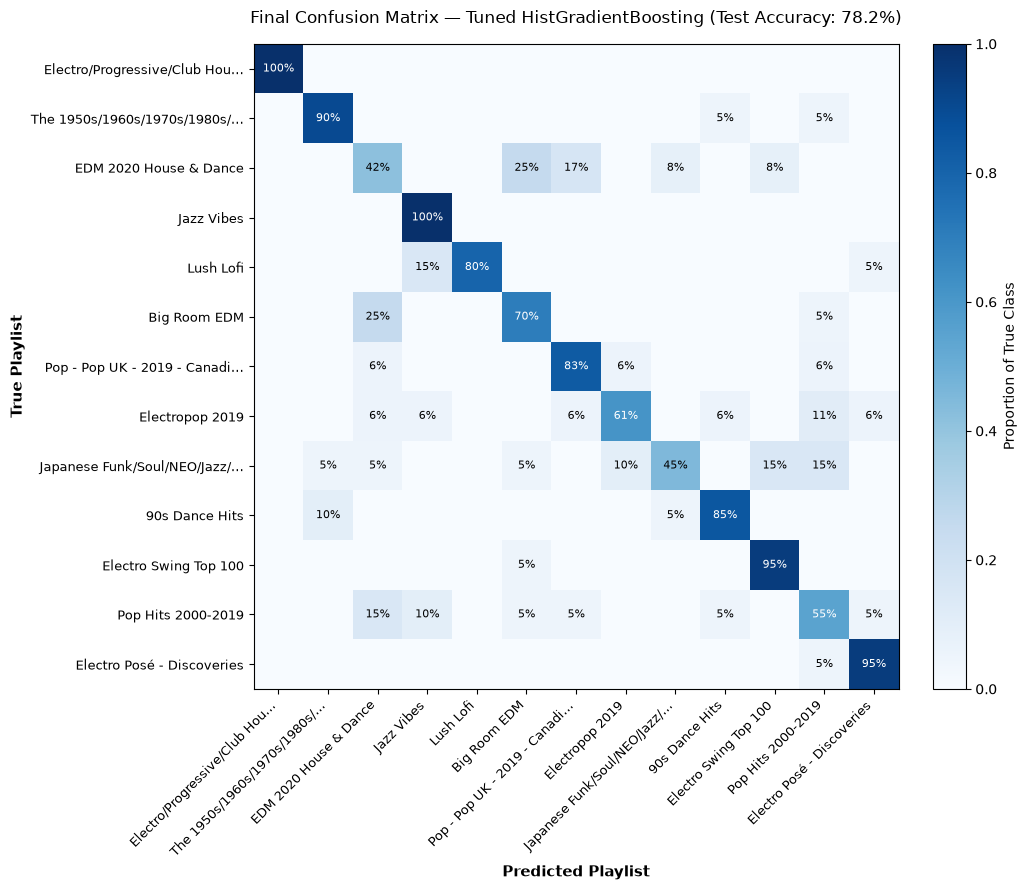

Saved -> artifacts/final_confusion_matrix.png


In [25]:
# ── Section 9.2: Final Row-Normalized Confusion Matrix Plot ───────────────────

cm_final_norm = confusion_matrix(y_test, y_pred_test, normalize="true")

fig, ax = plt.subplots(figsize=(11, 9))
cax = ax.imshow(cm_final_norm, cmap="Blues", vmin=0.0, vmax=1.0)
fig.colorbar(cax, ax=ax, fraction=0.046, pad=0.04, label="Proportion of True Class")

ax.set_xticks(range(N_PLAYLISTS))
ax.set_yticks(range(N_PLAYLISTS))
ax.set_xticklabels(short_class_names, rotation=45, ha="right", fontsize=9)
ax.set_yticklabels(short_class_names, fontsize=9)
ax.set_xlabel("Predicted Playlist", fontsize=11, fontweight="bold")
ax.set_ylabel("True Playlist", fontsize=11, fontweight="bold")
ax.set_title(f"Final Confusion Matrix — {champion_name} (Test Accuracy: {final_test_acc:.1%})", fontsize=12, pad=15)

for i in range(N_PLAYLISTS):
    for j in range(N_PLAYLISTS):
        val = cm_final_norm[i, j]
        if val >= 0.01:
            color = "white" if val > 0.50 else "black"
            ax.text(j, i, f"{val:.0%}", ha="center", va="center", color=color, fontsize=8)

plt.tight_layout()
plt.savefig(f"{ARTIFACTS}final_confusion_matrix.png", dpi=130)
plt.show()
print(f"Saved -> {ARTIFACTS}final_confusion_matrix.png")

In [26]:
# ── Section 9.3: Automated Error Analysis of Remaining Misclassifications ─────

final_errors = []
for i in range(N_PLAYLISTS):
    for j in range(N_PLAYLISTS):
        if i != j and cm_final_norm[i, j] > 0.0:
            raw_count = int(np.round(cm_final_norm[i, j] * (y_test == i).sum()))
            final_errors.append({
                "True Playlist": short_class_names[i],
                "Predicted Playlist": short_class_names[j],
                "Confusion Rate": cm_final_norm[i, j],
                "Misclassified Tracks": raw_count,
            })

df_final_errors = (
    pd.DataFrame(final_errors)
    .sort_values(by="Confusion Rate", ascending=False)
    .reset_index(drop=True)
)

print("=" * 80)
print("REMAINING CONFUSED PLAYLIST PAIRS (Ranked by Error Rate):")
print("=" * 80)
print(df_final_errors.head(8).to_string(index=False, formatters={
    "Confusion Rate": "{:.1%}".format,
}))
print("-" * 80)

REMAINING CONFUSED PLAYLIST PAIRS (Ranked by Error Rate):
                True Playlist            Predicted Playlist Confusion Rate  Misclassified Tracks
       EDM 2020 House & Dance                  Big Room EDM          25.0%                     3
                 Big Room EDM        EDM 2020 House & Dance          25.0%                     5
       EDM 2020 House & Dance Pop - Pop UK - 2019 - Canadi…          16.7%                     2
Japanese Funk/Soul/NEO/Jazz/…         Electro Swing Top 100          15.0%                     3
           Pop Hits 2000-2019        EDM 2020 House & Dance          15.0%                     3
                    Lush Lofi                    Jazz Vibes          15.0%                     3
Japanese Funk/Soul/NEO/Jazz/…            Pop Hits 2000-2019          15.0%                     3
              Electropop 2019            Pop Hits 2000-2019          11.1%                     2
---------------------------------------------------------------------